# 1) Loading the Taxis Dataset

In [5]:
import seaborn as sns
df = sns.load_dataset("taxis")

In [ ]:

df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

# 2) Handling Missing Values
➢ Check for missing values in the dataset and identify columns with missing data.

➢ Impute missing values using appropriate strategies based on the column type (e.g.,
using mean, median, or mode for numerical columns, and mode for categorical
columns).

➢ For columns that are critical and cannot be reasonably imputed, remove rows with
missing values to maintain data integrity.


In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


In [ ]:
df["payment"]=df["payment"].fillna(df["payment"].mode()[0])

In [ ]:
df["payment"].isnull().sum()

np.int64(0)

In [ ]:
df["pickup_zone"] = df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])

In [ ]:
df["dropoff_zone"] = df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])

In [ ]:
df["pickup_borough"] = df["pickup_borough"].fillna(df["pickup_borough"].mode()[0])

In [ ]:
df["dropoff_borough"] = df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0])

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


# Explanation
First we have to import seaborn which is a library so we use import seaborn as sns

now we load taxis dataset.To know the structure head() is used to show first 5 rows and info() is used to get all the information about the dataset

We have to check the missing values so isnull and sum is used it shows the no of missing values in each column and found 5 columns have missing values
To handle missing values with mode we use fillna() and mode() [0] means it finds the most frequent value

# 3) Visualizations using Matplotlib/Pandas Plot:
# ★ Line Chart  
Plot a line chart to visualize the fare over time, using the pickup timestamp as the
x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime
format before plotting.

In [ ]:
import pandas as pd

In [ ]:
df["pickup"]= pd.to_datetime(df["pickup"])

In [ ]:
import matplotlib.pyplot as plt


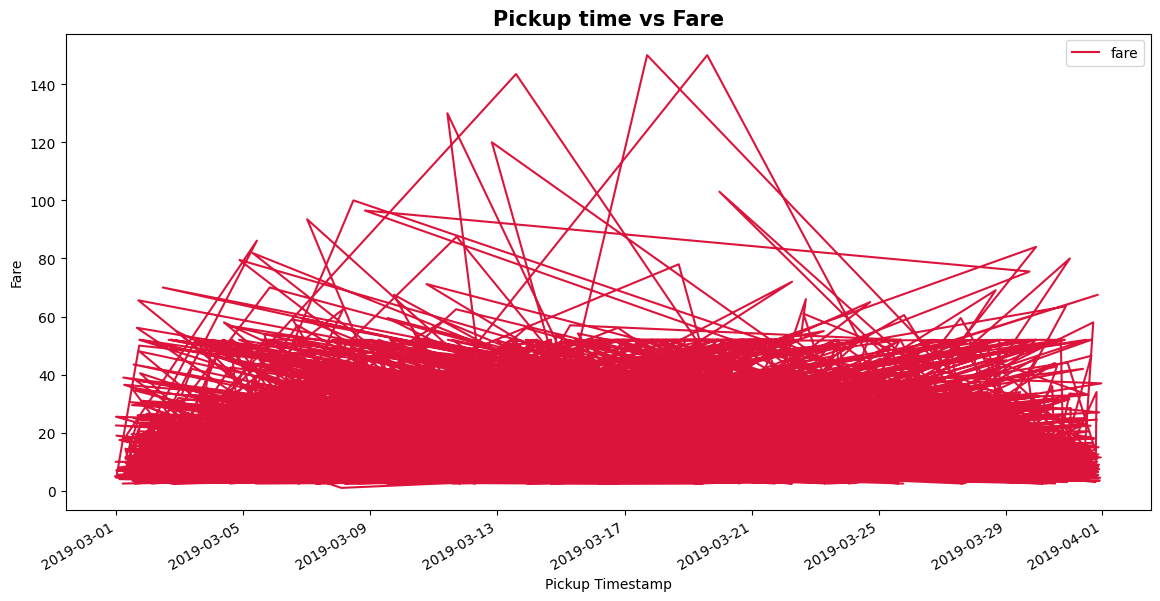

In [ ]:
df.plot(x="pickup", y="fare", kind="line",figsize=(14,7),color="crimson")
plt.title("Pickup time vs Fare",fontsize=15,fontweight="bold")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.show()

# Explanation
we have to import matplotlib it is a python library used to create graphs
Here we have to create a line chart so picup is in x axis and fare is in y axis kind=line means creating a line chart,figsize is the chart size,fontweight makes the tilte bold,color =crimson means it give the specific colour plt.xlabel and y label give labels to axes and show() makes the graph visible

Analysis: This line chart shows the relationship between pickup time and fare.Most fare are concentrated below 50 a few are higher fares

# ★ Bar Chart  
Create a bar chart to show the total fare for each pickup_borough. Group the data
by pickup_borough and sum the fare for each group.

In [ ]:
borough_fare = df.groupby('pickup_borough')['fare'].sum()

borough_fare

,fare
pickup_borough,
Bronx,2078.91
Brooklyn,6327.48
Manhattan,59426.42
Queens,16382.06


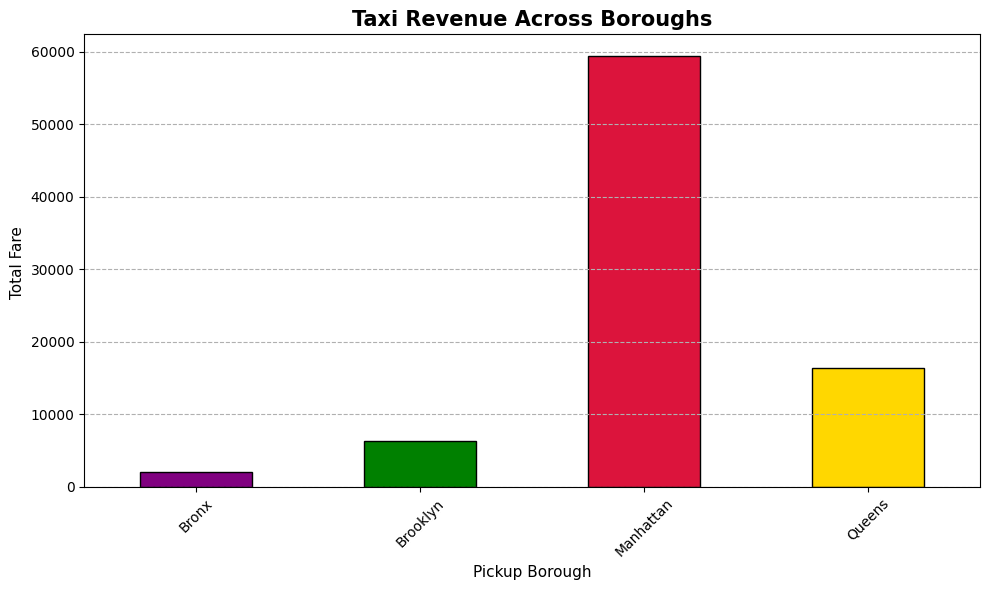

In [ ]:
borough_fare.plot(kind='bar',color=['purple', 'green', 'crimson', 'gold', 'blue'],figsize=(10, 6),edgecolor='black')

plt.title('Taxi Revenue Across Boroughs',fontsize=15, fontweight='bold')
plt.xlabel('Pickup Borough', fontsize=11)
plt.ylabel('Total Fare ', fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

# Explanation
First we have to find total fare of each pickup so we have to use borough_fare = df.groupby('pickup_borough')['fare'].sum() this groups all the rows according to the pickup borough
We give 4 different colurs to bars and make edge colour black Here rotation (45) means this rotate the labels by 45 degree to read them easier For adding gridlines grid() is used and axis y means horizontal gridlines. plt.tight_layout() means it automatically adjust spacing so the labels and titles never overlap

Analysis:Manhattan has the highest total fare and Bronx has the lowest


# ★ Pie Chart  
Plot a pie chart showing the distribution of trips based on the payment method (credit
card, cash, etc.). Each slice should represent the count of trips for a specific payment
method.

In [ ]:
payment_counts = df['payment'].value_counts()
payment_counts

,count
payment,
credit card,4577
cash,1812


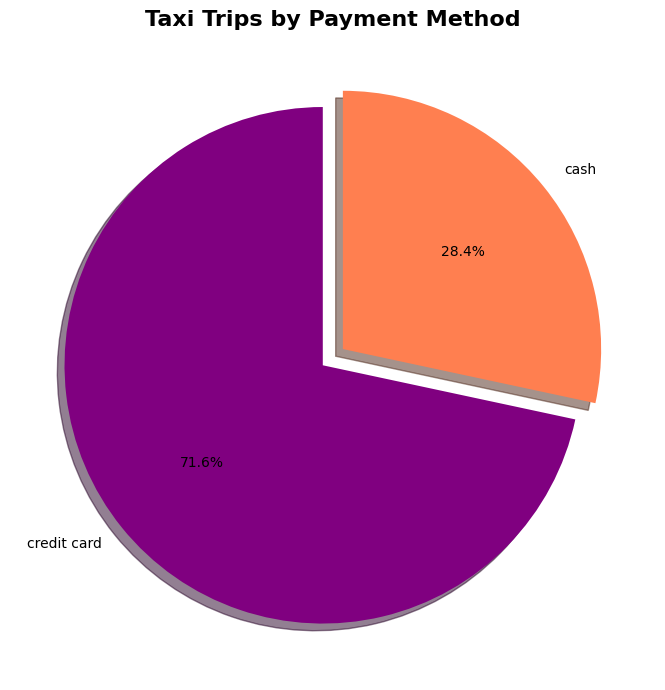

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))
plt.pie( payment_counts,labels=payment_counts.index,autopct='%1.1f%%',startangle=90,
    colors=['purple', 'coral'],explode=[0.05] * len(payment_counts),
    shadow=True)
plt.title('Taxi Trips by Payment Method',fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Explanation
First we have to count the trips by payment method so value_count() is used For pie plt.pie is used Here autopct='%1.1f%%' means disply the percentage on slicers.startangle=90 meansstart the chart from top.explode=[.05]*len means separate each slice slightly and for shadow =true for shadow effect

Analysis:This helps to understand how passengers pay for taxi trips.The credit card is more common

# ★ Histogram  
Create a histogram to visualize the distribution of distance. Customize the number of
bins for better granularity and ensure the plot is easy to interpret.

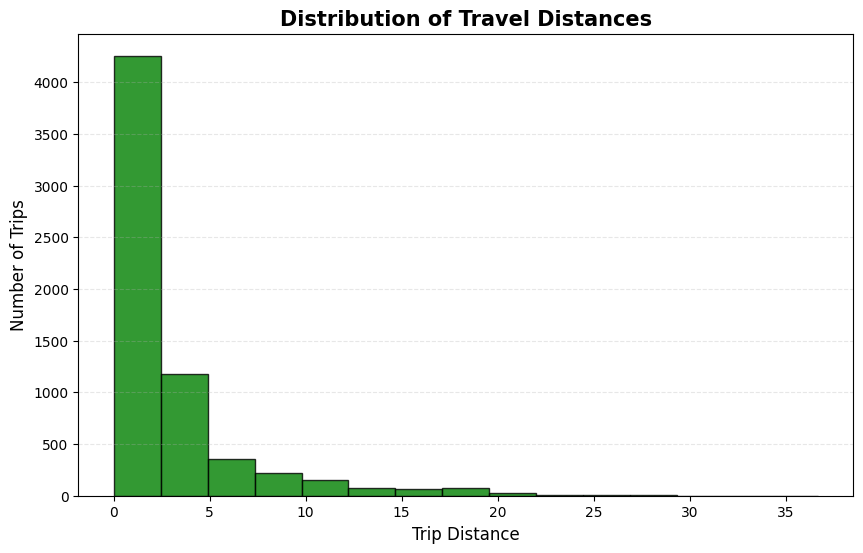

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df['distance'].dropna(),bins=15,color='green',edgecolor='black',alpha=0.8)

plt.title('Distribution of Travel Distances',fontsize=15, fontweight='bold')
plt.xlabel('Trip Distance', fontsize=12)
plt.ylabel('Number of Trips', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

# Explanation
For histogram plt.hist() is used
dropna() is used to avoid missing distance ,bins means divide the distance into 15 intervals.alpha means it control transperancy also used For adding gridlines grid() is used and axis y means horizontal gridlines. title() is for giving title

Anslysis:This is to understand how frequently different trip distance.When trip distance increase no of trips decreases

# ★ Box Plot  
Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
Use pickup_borough as the categorical axis and tip as the numeric axis.

<Figure size 1000x600 with 0 Axes>

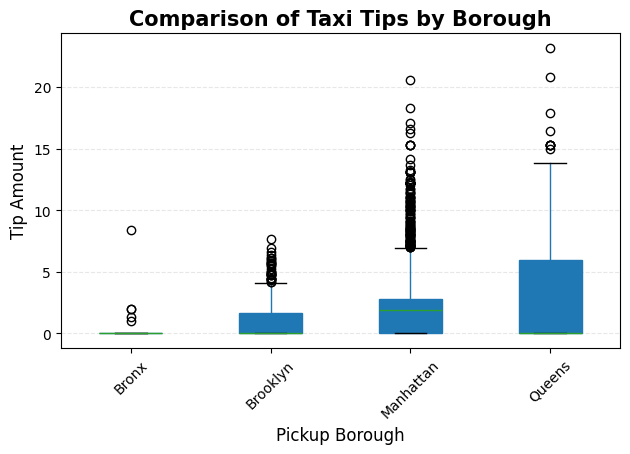

In [ ]:
plt.figure(figsize=(10, 6))
df.boxplot(column='tip',by='pickup_borough', patch_artist=True,grid=False)
plt.title('Comparison of Taxi Tips by Borough', fontsize=15, fontweight='bold')
plt.suptitle('')
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Tip Amount', fontsize=12)

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Explanation
For box plot df.boxplot() is used column=select the tip amount,by= means create a separate box for each borough,patchaatist true means allow boxes to fill colours ,plt.suptitle means avoid extra title

Analysis:Bronx has zero tips with few outliers.Manhattan has many outliers.Some trips receive higher tips than most others

# Visualizations using Seaborn
# ★ Count Plot  
Create a count plot to visualize the number of trips in each pickup_borough. The
x-axis should represent the boroughs, and the y-axis should show the count of trips.

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

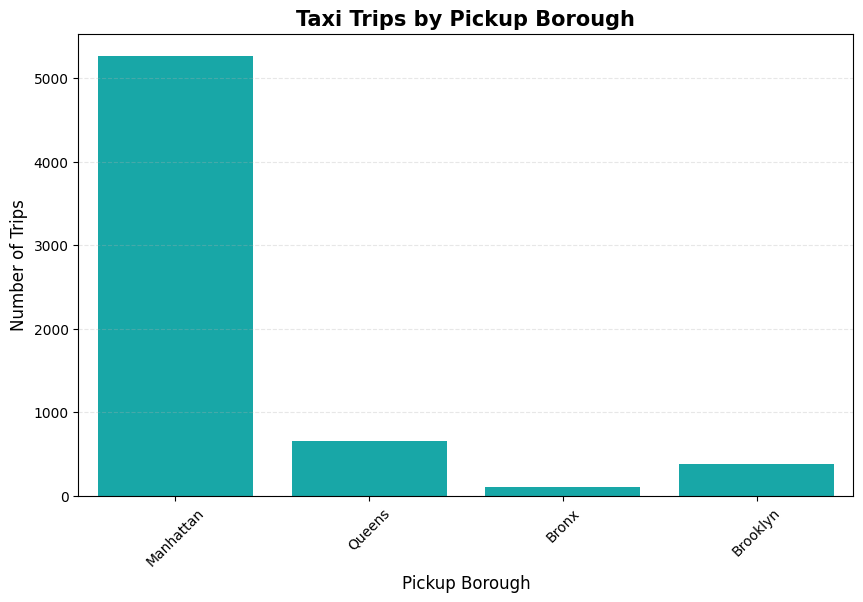

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df,x='pickup_borough',color='c')
plt.title('Taxi Trips by Pickup Borough',fontsize=15, fontweight='bold')
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Number of Trips', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

# Explanation
Count plot counts how many rows belong to each category
sns.count plot() is used to plot the chart data=df means use the taxies data,and give title() x and y labels() , grid() is used and line style is used and colour c means cyan

Analysis:Taxi pickups are heavely in Manhattan

# ★ Scatter Plot  
Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
points based on the pickup_borough to differentiate the trips by their respective
boroughs.

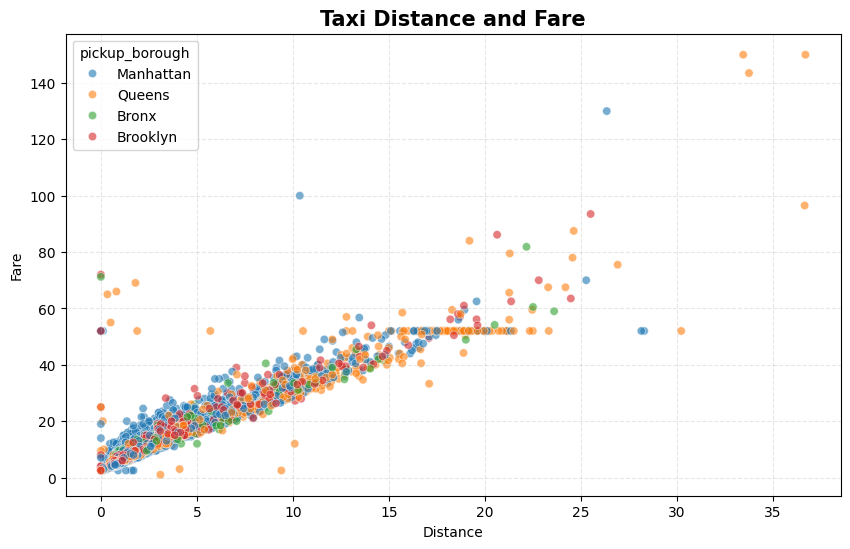

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,x='distance',y='fare',hue='pickup_borough',alpha=0.6)
plt.title('Taxi Distance and Fare',fontsize=15, fontweight='bold')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

# Explanation
A scatter plot shows individual data points we can see the relationship between 2 numerical variables
sns.scatterplot() is used hue means give differnt colours to each borough,alpha means it makes overlapping points eaiser to distingush

Analysis:It gives the idea that as trip distance increasaes fare also increasaes

# ★ Heatmap  
Plot a heatmap to visualize the correlation between numerical variables such as
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.

In [6]:
numeric_df = df[['distance', 'fare', 'tip', 'tolls', 'total']]

In [8]:
correlation_matrix = numeric_df.corr()
correlation_matrix

,distance,fare,tip,tolls,total
distance,1.000000,0.920108,0.452589,0.635267,0.904676
fare,0.920108,1.000000,0.488612,0.609307,0.974358
tip,0.452589,0.488612,1.000000,0.413619,0.646186
tolls,0.635267,0.609307,0.413619,1.000000,0.683142
total,0.904676,0.974358,0.646186,0.683142,1.000000


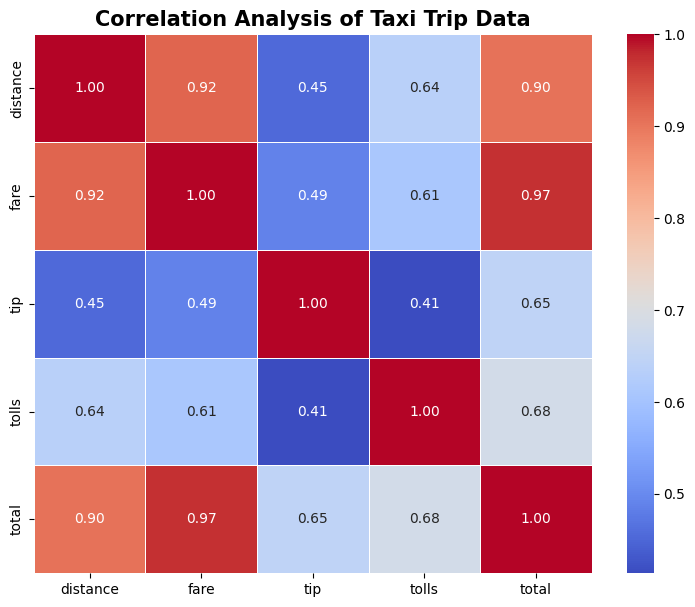

In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('Correlation Analysis of Taxi Trip Data',fontsize=15, fontweight='bold')
plt.show()

# Explanation
A heat map uses colours to represent numbers
First df select 5 columns,numeric stores those columns
now we have to calculate the correlation matrix so .corr() is used
For heat map sns.heatmap() is used annot means display correlation numbers in the cell,fmt means display value to 2 decimal point and coolwarm is the colour pallet used

Analysis:A strong positive correlation between distance and fare,fare and total,distance and total.Moderate with tip and total,tolls and total,tip and fare ,tip and tolls

# ★ Pair Plot  
Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
and total. Color the data points according to the pickup_zone method to compare
how different zones affect these variables

In [14]:
pair_df = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna()

In [15]:
pair_df['pickup_zone'].nunique()

194

KeyboardInterrupt: 

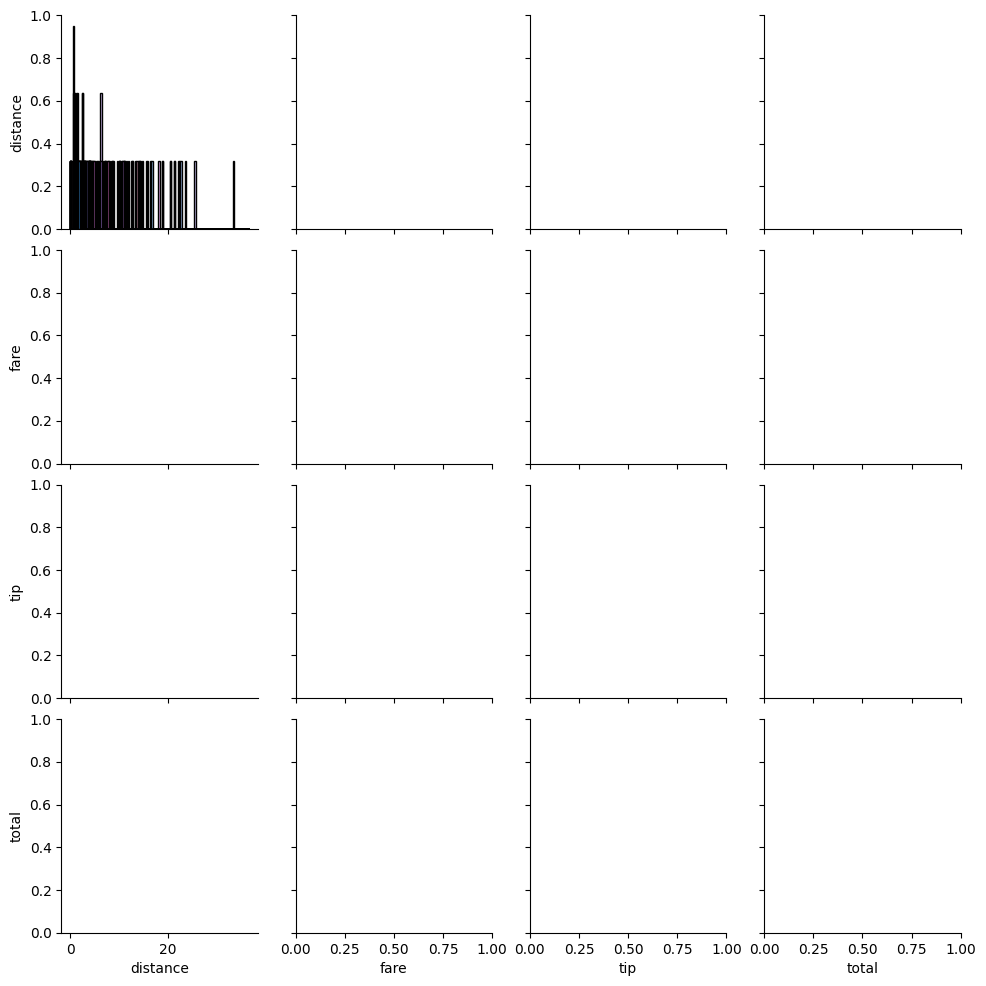

In [18]:
sns.pairplot(pair_df,vars=['distance', 'fare', 'tip', 'total'],hue='pickup_zone',diag_kind='hist',plot_kws={'alpha': 0.5, 's': 15})
plt.suptitle('Pairwise Relationships in Taxi Data', y=1.02,fontsize=15, fontweight='bold')
plt.show()

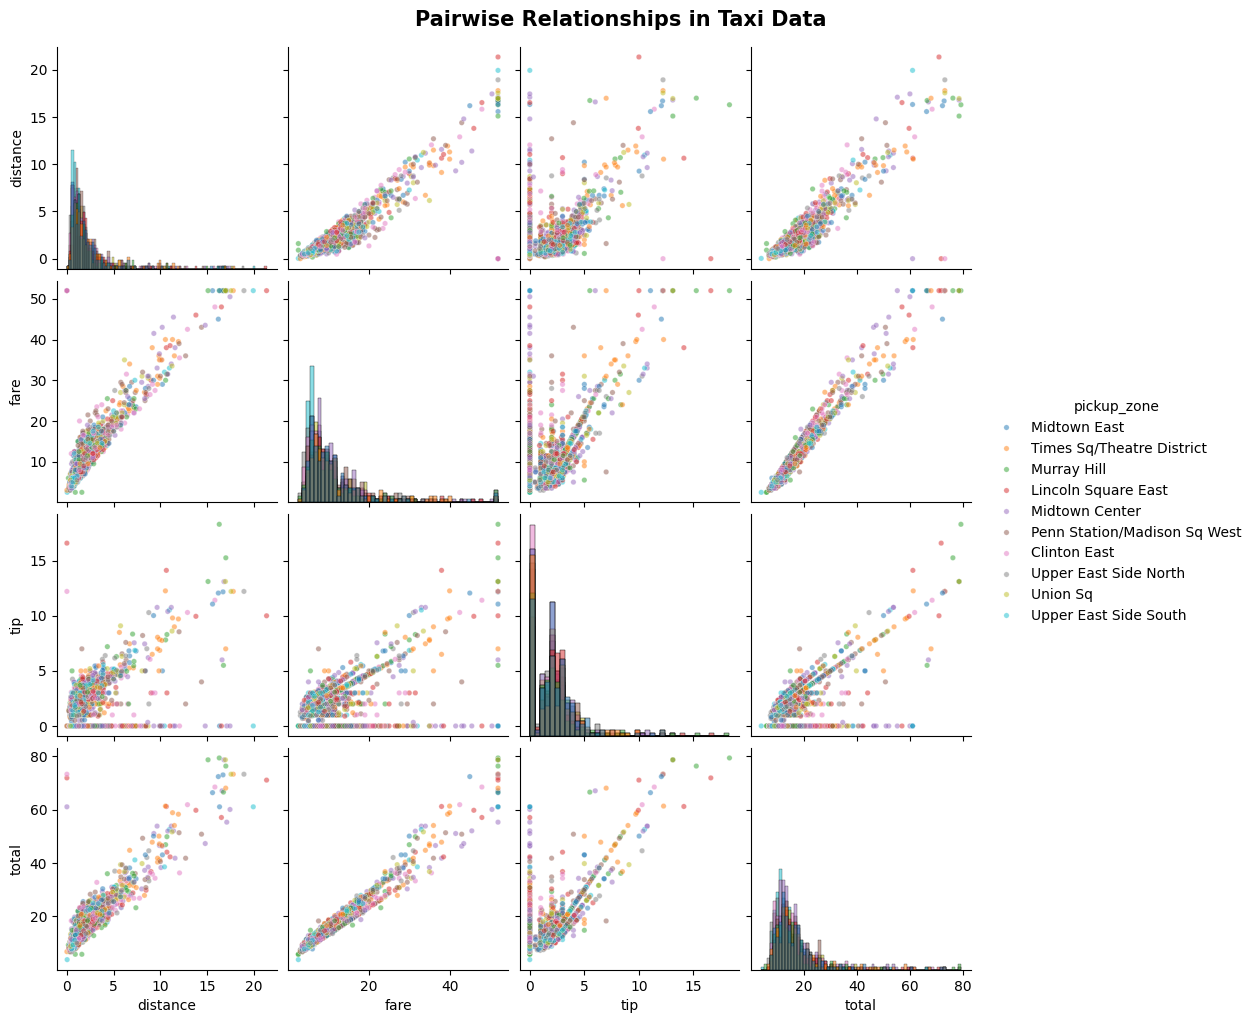

In [19]:
top_zones = df['pickup_zone'].value_counts().head(10).index
pair_df = df[
    df['pickup_zone'].isin(top_zones)][['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna()
sns.pairplot(pair_df, vars=['distance', 'fare', 'tip', 'total'],hue='pickup_zone',diag_kind='hist',plot_kws={'alpha': 0.5, 's': 15})
plt.suptitle("Pairwise Relationships in Taxi Data", y=1.02,fontsize=15,fontweight='bold')
plt.show()

# Explanation


pair_df stores the selected data,dropna remove the missing values,sns.pairplot() is used to create it.vars select the 4 varaibles ,dia_kind hist means show histogram along the diagonal,s=15 set the point size

Chart 2: First find 10 most common pickup zones by the code top_zones = df['pickup_zone'].value_counts().head(10).index
isin means it check each rows pickup zone is among the 10 .it give true if it contain otherwise false


Analysis: A pair plot gives a border view of numerical relationship and distribution

# ★ Violin Plot  
Plot a violin plot to show the distribution of fare for each payment method. Use the
payment method as the categorical axis and fare as the numeric axis to visualize its
distribution.

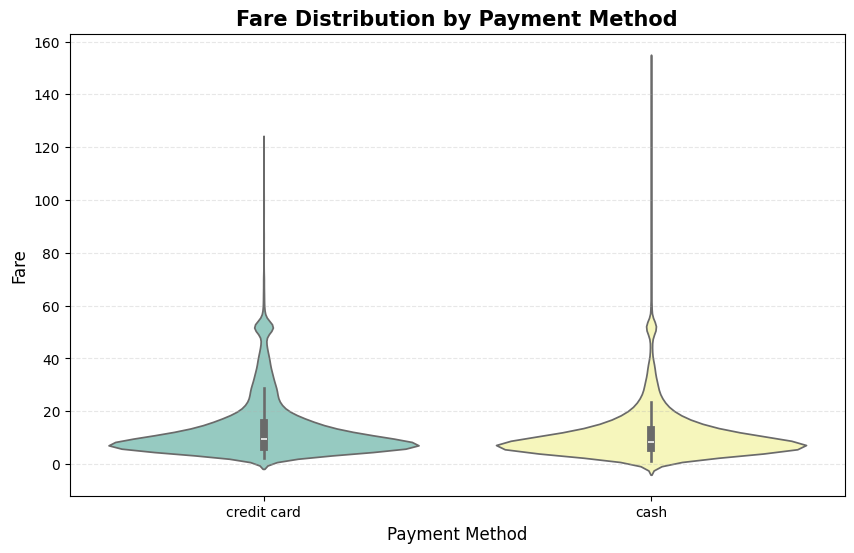

In [13]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df,x='payment', y='fare',hue='payment',palette='Set3',legend=False)
plt.title('Fare Distribution by Payment Method',fontsize=15, fontweight='bold')
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Fare', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

# Explanation
A violin plot shows how numerical values are distributed across different categories
For this sns.violinplot() is used,hue means colours the violins by paymnet method,legend false means hides the legend pallet set3 means appies a colour pallet

Analysis:Both payment methods have similar fare distribution